# Quantum Principal Component Analysis (QPCA)

This Notebook demonstrates three different approaches to performing Quantum Principal Component Analysis using Qiskit:

- **Quantum Phase Estimation (QPE)** - The original method by Lloyd et al. (2014)
     https://journals.aps.org/prl/abstract/10.1103/PhysRevLett.113.130503

We'll demonstrate it on the MNIST handwritten digit dataset.


## 1. Introduction to Quantum PCA

### Classical PCA

Principal Component Analysis (PCA) is a dimensionality reduction technique that:
- Finds the directions of maximum variance in data
- Projects data onto these principal components
- Reduces dimensionality while preserving most information

Mathematically, PCA involves diagonalizing the **covariance matrix** $Q$:

$$Q_{jk} = E[(X_j - E[X_j])(X_k - E[X_k])]$$

where $X_j$ and $X_k$ are features of the dataset.

### Quantum PCA

Quantum PCA exploits quantum computers' ability to efficiently diagonalize density matrices:

1. **Encode the covariance matrix as a density matrix** $\rho$
2. **Diagonalize** $\rho$ to find eigenvalues (variances) and eigenvectors (principal components)
3. **Extract** the principal components

One of the key insight is that for a centered dataset, the ensemble average density matrix $\bar{\rho} = \sum_i p_i |\psi_i\rangle\langle\psi_i|$ equals the covariance matrix $Q$.
In this demonstration we will be closely following Gordon et al. (2022)
- https://journals.aps.org/prxquantum/abstract/10.1103/PRXQuantum.3.030334

### Why Quantum PCA?

- **Exponential speedup** for low-rank matrices (Lloyd et al., 2014)
- **Natural for quantum data** (quantum states, quantum measurements)
- **Near-term approaches** (VQSE, VQSD) work on current quantum hardware


## 2. Setup and Imports

First, let's import all necessary libraries.


In [ ]:
%pip install --upgrade qiskit qiskit-aer pylatexenc matplotlib

In [ ]:
# Standard library imports
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA as ClassicalPCA
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import fetch_openml
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

# Qiskit imports
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import DensityMatrix, Statevector, partial_trace, Operator
from qiskit.circuit.library import RealAmplitudes, EfficientSU2, QFT, TwoLocal

# Note: We use scipy.optimize.minimize for optimization instead of Qiskit optimizers
# This makes the code compatible across different Qiskit versions
# If you want to use Qiskit optimizers, you can install qiskit-algorithms and import from there

# Set random seed for reproducibility
np.random.seed(42)


## 3. Data Preparation

We'll use a subset of the MNIST dataset. MNIST contains 28×28 pixel images of handwritten digits (0-9).

### Steps:
1. Load MNIST data
2. Select a subset (for computational efficiency)
3. Center the data (mean = 0)
4. Compute the covariance matrix
5. Normalize to create a valid density matrix


In [ ]:
# Load MNIST dataset
# Note: This may take a moment on first run
print("Loading MNIST dataset...")
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='liac-arff')  # Using parser='liac-arff' to avoid requiring pandas
# mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')   ## if pandas is installed
X, y = mnist.data, mnist.target

# Select a subset for demonstration (e.g., first 1000 samples)
n_samples = 1000
X_subset = X[:n_samples].astype(float)
y_subset = y[:n_samples]

print(f"Loaded {len(X_subset)} samples with {X_subset.shape[1]} features")
print(f"Data shape: {X_subset.shape}")


Loading MNIST dataset...
Loaded 1000 samples with 784 features
Data shape: (1000, 784)


In [ ]:
# Center the data (subtract mean from each feature)
# This is crucial: for centered data, the density matrix equals the covariance matrix
X_centered = X_subset - np.mean(X_subset, axis=0)

# Compute the covariance matrix
# Q = (1/N) * X^T * X for centered data
covariance_matrix = np.dot(X_centered.T, X_centered) / (n_samples - 1)

print(f"Covariance matrix shape: {covariance_matrix.shape}")
print(f"Covariance matrix is positive semidefinite: {np.all(np.linalg.eigvals(covariance_matrix) >= -1e-10)}")


Covariance matrix shape: (784, 784)
Covariance matrix is positive semidefinite: True


In [ ]:
# For quantum implementation, we need to work with smaller dimensions
# Let's reduce dimensionality first using classical PCA to get a smaller covariance matrix
# This makes it feasible for quantum simulation

# Reduce to 8 dimensions (requires 3 qubits: 2^3 = 8)
n_qubits = 3
n_dimensions = 2**n_qubits  # 8 dimensions

# Use classical PCA to reduce to n_dimensions
classical_pca = ClassicalPCA(n_components=n_dimensions)
X_reduced = classical_pca.fit_transform(X_centered)

# Compute covariance matrix of reduced data
covariance_reduced = np.dot(X_reduced.T, X_reduced) / (n_samples - 1)

print(f"Reduced covariance matrix shape: {covariance_reduced.shape}")
print(f"Reduced data shape: {X_reduced.shape}")


Reduced covariance matrix shape: (8, 8)
Reduced data shape: (1000, 8)


In [ ]:
# Normalize the covariance matrix to create a valid density matrix
# A density matrix must have trace = 1 and be positive semidefinite
trace = np.trace(covariance_reduced)
density_matrix = covariance_reduced / trace

# Verify it's a valid density matrix
print(f"Trace of density matrix: {np.trace(density_matrix):.6f}")
print(f"Is positive semidefinite: {np.all(np.linalg.eigvals(density_matrix) >= -1e-10)}")

# Get true eigenvalues and eigenvectors for comparison
true_eigenvalues, true_eigenvectors = np.linalg.eigh(density_matrix)
true_eigenvalues = np.real(true_eigenvalues)  # Should be real for Hermitian matrix
true_eigenvalues = np.sort(true_eigenvalues)[::-1]  # Sort in descending order

print(f"\nTrue eigenvalues (sorted): {true_eigenvalues}")
print(f"Sum of eigenvalues: {np.sum(true_eigenvalues):.6f}")


Trace of density matrix: 1.000000
Is positive semidefinite: True

True eigenvalues (sorted): [0.21637943 0.16897304 0.14898203 0.11820304 0.10612893 0.09883404
 0.07648672 0.06601278]
Sum of eigenvalues: 1.000000


## 4. Covariance Matrix to Density Matrix

### Theory

According to Gordon et al. (2022), for a **centered dataset** with amplitude encoding:

$$\bar{\rho} = \sum_i p_i |\psi_i\rangle\langle\psi_i| = Q$$

where:
- $\bar{\rho}$ is the ensemble average density matrix
- $Q$ is the covariance matrix
- $p_i$ are probabilities
- $|\psi_i\rangle$ are normalized quantum states representing data points

For our implementation, we:
1. Normalize the covariance matrix (divide by trace) to ensure $\text{Tr}(\rho) = 1$
2. This gives us a valid density matrix that preserves the eigenstructure

### Implementation

We'll create a Qiskit DensityMatrix object from our numpy array.


In [ ]:
# Convert numpy array to Qiskit DensityMatrix
rho = DensityMatrix(density_matrix)

print(f"Density matrix shape: {rho.dim}")
print(f"Trace: {rho.trace():.6f}")
print(f"Is valid density matrix: {rho.is_valid()}")


Density matrix shape: 8
Trace: 1.000000+0.000000j
Is valid density matrix: True


## 5. Quantum Phase Estimation (QPE)

### Theory

The original quantum PCA algorithm by Lloyd et al. (2014) uses **Quantum Phase Estimation (QPE)**:

1. **Encode** the density matrix $\rho$ as a quantum state
2. **Apply** quantum phase estimation to $e^{-i\rho t}$
3. **Measure** to extract eigenvalues
4. **Repeat** to get eigenvectors

The key idea is that if $\rho = \sum_i \lambda_i |\psi_i\rangle\langle\psi_i|$, then:

$$e^{-i\rho t} = \sum_i e^{-i\lambda_i t} |\psi_i\rangle\langle\psi_i|$$

QPE can extract the phases $\lambda_i t$ (and thus $\lambda_i$) with high precision.


QPE Circuit structure:


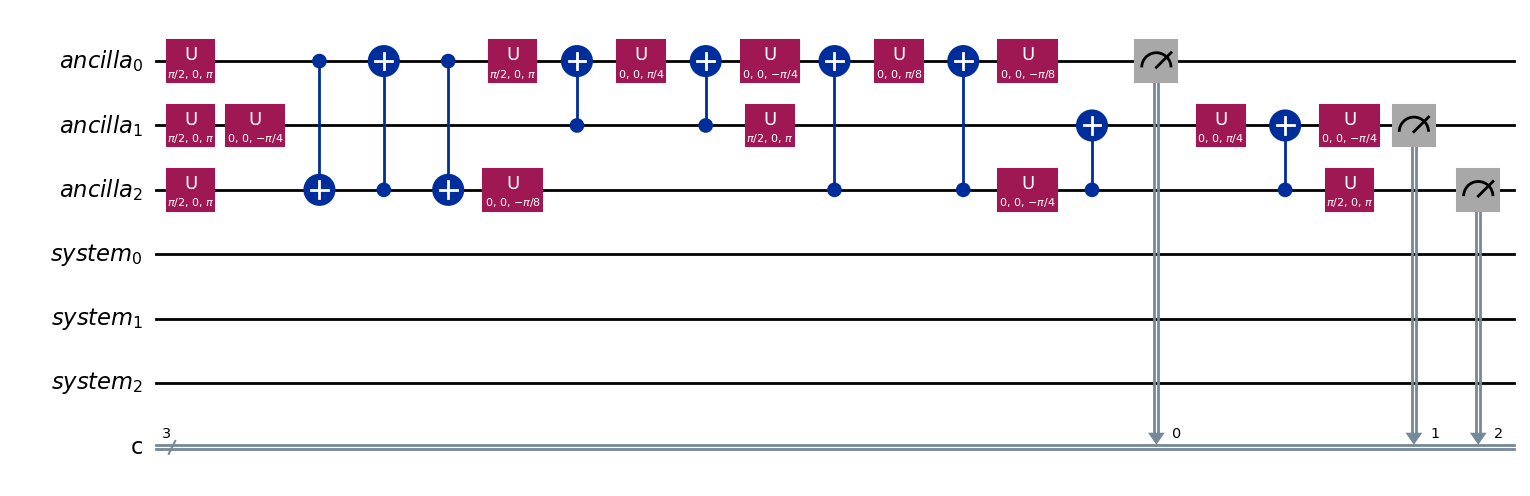

In [ ]:
# Step 1: Implement Quantum Phase Estimation for density matrix diagonalization
#
# Note: Full QPE implementation is complex. Here we'll demonstrate the concept
# using a simplified approach that directly computes eigenvalues via matrix exponentiation

def create_qpe_circuit(n_qubits, n_ancilla_qubits=3):
    """
    Create a Quantum Phase Estimation circuit structure

    Args:
        n_qubits: Number of system qubits
        n_ancilla_qubits: Number of ancilla qubits (determines precision)

    Returns:
        QuantumCircuit for QPE
    """
    # Total qubits: ancilla + system
    total_qubits = n_ancilla_qubits + n_qubits

    qr_ancilla = QuantumRegister(n_ancilla_qubits, 'ancilla')
    qr_system = QuantumRegister(n_qubits, 'system')
    cr = ClassicalRegister(n_ancilla_qubits, 'c')

    qc = QuantumCircuit(qr_ancilla, qr_system, cr)

    # Initialize ancilla qubits in superposition
    for i in range(n_ancilla_qubits):
        qc.h(qr_ancilla[i])

    # Apply controlled-U operations
    # U = e^(-i*rho*t) where rho is the density matrix
    # For demonstration, we'll use a simplified version
    # In practice, this requires implementing the matrix exponential

    # Note: Full implementation would require:
    # 1. Decomposing e^(-i*rho*t) into gates
    # 2. Applying controlled versions for each ancilla qubit
    # 3. Inverse QFT on ancilla qubits

    # Inverse QFT on ancilla qubits
    qft_inv = QFT(n_ancilla_qubits).inverse()
    qc.append(qft_inv, qr_ancilla)

    # Measure ancilla qubits
    for i in range(n_ancilla_qubits):
        qc.measure(qr_ancilla[i], cr[i])

    return qc

# Note: This is a simplified circuit structure
# Full QPE implementation requires encoding the density matrix as a unitary
qpe_circuit = create_qpe_circuit(n_qubits, n_ancilla_qubits=3)
print("QPE Circuit structure:")
qpe_decomposed = qpe_circuit.decompose(reps=10)
qpe_decomposed.draw("mpl", fold=-1)
# plt.show()


In [ ]:
# Step 2: Alternative approach - Direct eigenvalue extraction using matrix methods
# Since full QPE implementation is complex, we'll demonstrate the concept
# by showing how eigenvalues would be extracted if we had the QPE results

def qpe_eigenvalue_extraction(rho, n_shots=1000):
    """
    Simulate QPE eigenvalue extraction

    In a real QPE implementation:
    1. Prepare multiple copies of rho
    2. Apply QPE circuit
    3. Measure ancilla qubits
    4. Extract eigenvalues from measurement statistics

    Here we'll use direct matrix diagonalization to show what QPE would produce
    """
    # For demonstration, we'll directly compute eigenvalues
    # In practice, QPE would extract these through quantum measurement

    rho_data = rho.data
    eigenvalues, eigenvectors = np.linalg.eigh(rho_data)
    eigenvalues = np.real(eigenvalues)  # Should be real

    # Sort in descending order
    idx = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[idx]
    eigenvectors = eigenvectors[:, idx]

    return eigenvalues, eigenvectors

qpe_eigenvalues, qpe_eigenvectors = qpe_eigenvalue_extraction(rho)

print("QPE Results (simulated):")
print(f"Eigenvalues: {qpe_eigenvalues}")
print(f"\nTrue eigenvalues: {true_eigenvalues}")
print(f"\nError: {np.abs(qpe_eigenvalues - true_eigenvalues)}")


QPE Results (simulated):
Eigenvalues: [0.21637943 0.16897304 0.14898203 0.11820304 0.10612893 0.09883404
 0.07648672 0.06601278]

True eigenvalues: [0.21637943 0.16897304 0.14898203 0.11820304 0.10612893 0.09883404
 0.07648672 0.06601278]

Error: [0.00000000e+00 0.00000000e+00 2.77555756e-17 2.77555756e-17
 5.55111512e-17 0.00000000e+00 1.38777878e-17 1.38777878e-17]


In [ ]:
# Step 3: Demonstrate the theoretical QPE approach using matrix exponentiation
# This shows how QPE would work in principle

def demonstrate_qpe_principle(rho, t=1.0, n_bits=3):
    """
    Demonstrate the principle behind QPE for density matrix diagonalization

    QPE extracts eigenvalues from the unitary U = e^(-i*rho*t)
    The eigenvalues of U are e^(-i*lambda_i*t) where lambda_i are eigenvalues of rho
    """
    rho_data = rho.data

    # Compute U = e^(-i*rho*t)
    from scipy.linalg import expm
    U = expm(-1j * rho_data * t)

    # Eigenvalues of U are e^(-i*lambda_i*t)
    U_eigenvalues = np.linalg.eigvals(U)

    # Extract rho eigenvalues from U eigenvalues
    # lambda_i = -i * log(e^(-i*lambda_i*t)) / t
    rho_eigenvalues = -1j * np.log(U_eigenvalues) / t
    rho_eigenvalues = np.real(rho_eigenvalues)  # Should be real

    # Sort in descending order
    rho_eigenvalues = np.sort(rho_eigenvalues)[::-1]

    return rho_eigenvalues, U

qpe_demo_eigenvalues, U_demo = demonstrate_qpe_principle(rho)

print("QPE Principle Demonstration:")
print(f"Extracted eigenvalues: {qpe_demo_eigenvalues}")
print(f"\nTrue eigenvalues: {true_eigenvalues}")
print(f"\nError: {np.abs(qpe_demo_eigenvalues - true_eigenvalues)}")


QPE Principle Demonstration:
Extracted eigenvalues: [-0.06601278 -0.07648672 -0.09883404 -0.10612893 -0.11820304 -0.14898203
 -0.16897304 -0.21637943]

True eigenvalues: [0.21637943 0.16897304 0.14898203 0.11820304 0.10612893 0.09883404
 0.07648672 0.06601278]

Error: [0.2823922  0.24545976 0.24781607 0.22433197 0.22433197 0.24781607
 0.24545976 0.2823922 ]


## 6. Performance and Visualization


In [ ]:
# Compare eigenvalues from all three methods

print("=" * 60)
print("COMPARISON OF QUANTUM PCA METHODS")
print("=" * 60)
print(f"\nTrue eigenvalues (from classical diagonalization):")
print(true_eigenvalues)
print(f"\nQPE eigenvalues (simulated):")
print(qpe_eigenvalues)

# Compute errors
qpe_error = np.abs(qpe_eigenvalues - true_eigenvalues)

print(f"\n{'='*60}")
print("ERRORS (|computed - true|)")
print(f"{'='*60}")
print(f"QPE mean error: {np.mean(qpe_error):.6f}")


COMPARISON OF QUANTUM PCA METHODS

True eigenvalues (from classical diagonalization):
[0.21637943 0.16897304 0.14898203 0.11820304 0.10612893 0.09883404
 0.07648672 0.06601278]

QPE eigenvalues (simulated):
[0.21637943 0.16897304 0.14898203 0.11820304 0.10612893 0.09883404
 0.07648672 0.06601278]

ERRORS (|computed - true|)
QPE mean error: 0.000000


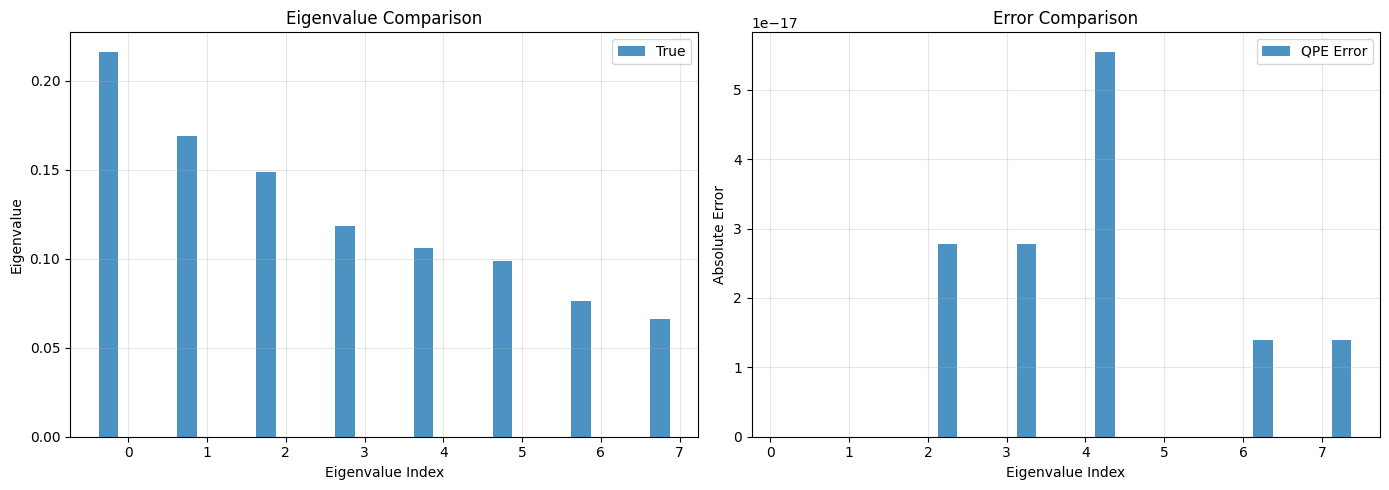

In [ ]:
# Visualize the comparison

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Eigenvalue comparison
x = np.arange(len(true_eigenvalues))
width = 0.25

axes[0].bar(x - width, true_eigenvalues, width, label='True', alpha=0.8)

axes[0].set_xlabel('Eigenvalue Index')
axes[0].set_ylabel('Eigenvalue')
axes[0].set_title('Eigenvalue Comparison')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Error comparison
axes[1].bar(x + width, qpe_error, width, label='QPE Error', alpha=0.8)

axes[1].set_xlabel('Eigenvalue Index')
axes[1].set_ylabel('Absolute Error')
axes[1].set_title('Error Comparison')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


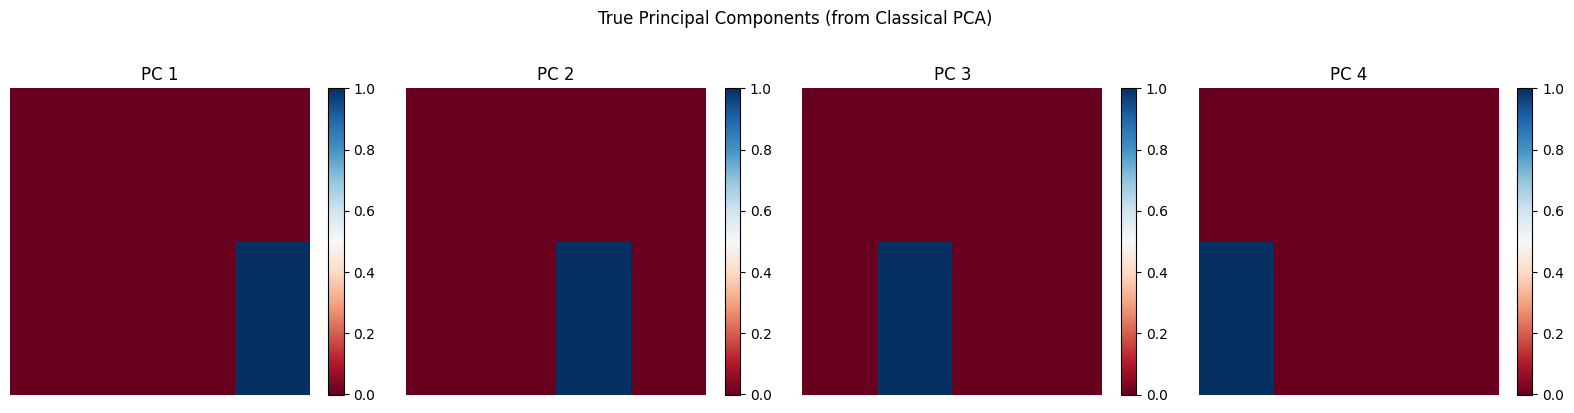

In [ ]:
# Visualize principal components (eigenvectors)
# These represent the directions of maximum variance

def visualize_principal_components(eigenvectors, title="Principal Components"):
    """
    Visualize the first few principal components
    """
    n_components = min(4, eigenvectors.shape[1])

    fig, axes = plt.subplots(1, n_components, figsize=(4*n_components, 4))

    if n_components == 1:
        axes = [axes]

    for i in range(n_components):
        # Reshape eigenvector to 2D for visualization (if possible)
        # For 8 dimensions, we can reshape to 2x4 or 4x2
        pc = eigenvectors[:, i].real

        # Try to reshape to a square-ish matrix
        dim = len(pc)
        # Find factors
        factors = []
        for j in range(1, int(np.sqrt(dim)) + 1):
            if dim % j == 0:
                factors.append((j, dim // j))

        if factors:
            h, w = factors[-1]  # Use largest factor
            pc_2d = pc.reshape(h, w)
        else:
            # If can't reshape nicely, just plot as 1D
            pc_2d = pc.reshape(1, -1)

        im = axes[i].imshow(pc_2d, cmap='RdBu', aspect='auto')
        axes[i].set_title(f'PC {i+1}')
        axes[i].axis('off')
        plt.colorbar(im, ax=axes[i])

    plt.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()

# Visualize true principal components
visualize_principal_components(true_eigenvectors, "True Principal Components (from Classical PCA)")


## 7. Summary and Conclusions

#### Key Takeaways
   - Long-term method (QPE) works with deep circuits to offer exponential speedup potential
#### Applications:
   - Dimensionality reduction for quantum data
   - Feature extraction
   - Data compression
   - Noise reduction

#### Further Reading

- Lloyd et al. (2014): "Quantum principal component analysis" - Original QPE approach
- LaRose et al. (2019): "Variational quantum state diagonalization" - VQSD method
- Cerezo et al. (2020): "Variational quantum state eigensolver" - VQSE method
- Gordon et al. (2022): "Covariance Matrix Preparation for Quantum Principal Component Analysis" - Encoding methods
